In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

data=pd.read_csv("../../files/data.csv")

y=data["SP500"].values
y1 = np.convolve(y, [1/100]*100)

K=20
for i in range(K):
    if i > 0:
        X = np.concatenate((X, y1[i:-K+i, np.newaxis]), axis=-1)
    else:
        X = y1[i:-K+i, np.newaxis].copy()

Y=y1[K:]
print(X.shape, Y.shape)


(1948, 20) (1948,)


Epoch 1/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1722668.6250 - val_loss: 1344114.1250
Epoch 2/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 565573.0625 - val_loss: 352590.8750
Epoch 3/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 132084.0625 - val_loss: 77316.0312
Epoch 4/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 25229.5625 - val_loss: 19216.9102
Epoch 5/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7589.0991 - val_loss: 10135.6514
Epoch 6/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5798.8770 - val_loss: 8674.1582
Epoch 7/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5582.8042 - val_loss: 8712.1582
Epoch 8/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5552.6753 - val_loss: 8491.7217
Epoch 9/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5472.8921 - val_loss: 8537.7324
Epoch 10/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5432.5713 - val_loss: 8351.1748
Epoch 11/1000
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 54

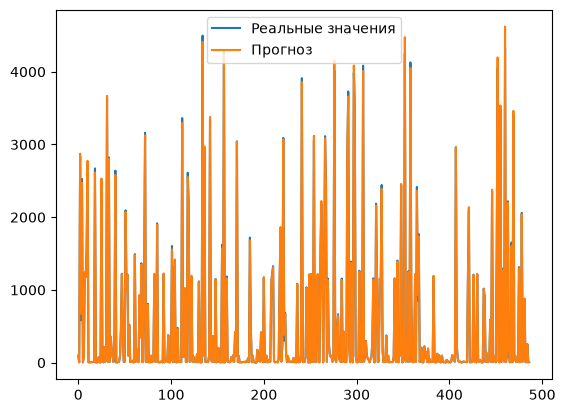

In [19]:
from sklearn.model_selection import train_test_split

model=tf.keras.models.Sequential()
model.add(tf.keras.layers.Input(shape=(K,)))
model.add(tf.keras.layers.Dense(1,activation='linear',kernel_regularizer='l1', bias_regularizer='l1'))

xtr,xtest,ytr,ytest=train_test_split(X,Y)

model.compile(optimizer='Adam',loss='mse')
es=tf.keras.callbacks.EarlyStopping(patience=5, mode='min', monitor='val_loss')
model.fit(xtr, ytr, epochs=1000, validation_split=0.2, callbacks=[es])

yp=model.predict(xtest)

plt.plot(ytest, label='Реальные значения')
plt.plot(yp, label='Прогноз')
plt.legend()

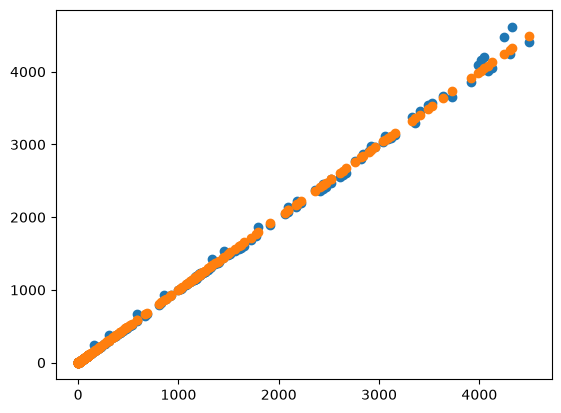

In [20]:
plt.scatter(ytest, yp)
plt.scatter(ytest, ytest)